In [48]:
import pandas as pd
import numpy as np
from tqdm import tqdm
from scipy import stats

from rdkit import Chem
from rdkit.Chem.rdFingerprintGenerator import GetMorganGenerator

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn import metrics
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import matthews_corrcoef

# from xgboost import XGBClassifier

import matplotlib.pyplot as plt

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
device

device(type='mps')

In [49]:
class Autoencoder(nn.Module):
    def __init__(self, input_dim=2048, embedding_dim=128):
        super().__init__()
        hidden_dim = embedding_dim * 2
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, embedding_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(embedding_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        y = self.decoder(z)
        return y, z

In [3]:
def train_test_split(images, n_train_per_class):

    """
    images is a list of images per class, ex: [img0, img1]
    """

    train = []
    test = []
    for img in images:
        n_c = len(img)
        ind_train = set(np.random.choice(n_c, n_train_per_class, replace=False).tolist())
        ind_test = set(range(n_c)) - ind_train
        train.append(img[list(ind_train)])
        test.append(img[list(ind_test)])
    return train, test


def classification_metrics(target, pred):
    tn, fp, fn, tp = metrics.confusion_matrix(target, pred).ravel()
    acc = (tp + tn) / (tn + fp + fn + tp)
    sen = tp / (tp + fn)
    spc = tn / (tn + fp)
    prc = tp / (tp + fp)
    mcc = ((tp * tn) - (fp * fn)) / ((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn) + .00000001) ** 0.5
    return acc, sen, spc, prc, mcc

In [50]:
df_po = pd.read_csv("data/PO_norm_analysed_16may.csv", index_col=0)
df = pd.read_csv("data/ligend_smiles_cononical.csv", index_col=0)
df_po['Protein'].unique()

/var/folders/g9/1n3d85nn2d14mq2r60k26ddc0000gn/T/ipykernel_36852/3263902071.py:1: DtypeWarning: Columns (24) have mixed types. Specify dtype option on import or set low_memory=False.
  df_po = pd.read_csv("data/PO_norm_analysed_16may.csv", index_col=0)


array(['PAH-WT', 'failed', 'PAH-I65T'], dtype=object)

In [51]:
df_po_protein = df_po.loc[df_po['Protein'] == 'PAH-WT', ['ID', 'bind_combined', 'Binding_validated_by_TSA']]
df = pd.merge(df, df_po_protein, on='ID')
# df = df.loc[df['Binding_validated_by_TSA'] != 'weak_evidence']
df.head()

,ID,SMILES,bind_combined,Binding_validated_by_TSA
0,CSCS00104537142,CC(C(=O)N1CCC(C(=O)O)(C(F)(F)F)C1)n1cncn1,weak_evidence,weak_evidence
1,CSCS00133135693,Cc1noc(C2CCN(C(=O)Nc3ccc(F)c(F)c3F)CC2)n1,no_evidence,no_evidence
2,CSCS00093835758,CN(CC(=O)NC1CCS(=O)(=O)C1)c1ncnc2ccsc12,no_evidence,weak_evidence
3,CSCS00133112516,Cn1ccnc1CN1CCN(C(=O)Nc2ccc(OC3CCOC3)cc2)CC1,weak_evidence,weak_evidence
4,CSCS00133028662,Cc1nn(-c2ccccc2)cc1CNC1[C@@H]2CCO[C@@H]2C1(C)C,weak_evidence,strong_evidence


In [52]:
df.shape

(79800, 4)

In [53]:
# Convert smiles into fingerprints

fpBits_all = []
for smiles in tqdm(df['SMILES']):
    mol = Chem.MolFromSmiles(smiles)
    generator = GetMorganGenerator(radius=2, fpSize=2048)
    fp = generator.GetFingerprint(mol)
    fpBits = np.array(fp) #.tolist()
    fpBits_all.append(fpBits)
    
fpBits_all = np.array(fpBits_all)
np.save("data/ligend_fingerprints.npy", fpBits_all)
fpBits_all

100%|█████████████████████████████████████| 79800/79800 [01:11<00:00, 1113.43it/s]


array([[0, 1, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 1],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 1, 0, ..., 0, 0, 0],
       [0, 1, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

In [21]:
# Define autoencoder, optimizer, and loss
embedding_dim = 512
model = Autoencoder(embedding_dim=embedding_dim).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.BCELoss()

In [22]:
batch_size = 1024
fpBits_all = np.load("data/ligend_fingerprints.npy")
fpBits_all = torch.tensor(fpBits_all, dtype=torch.float)
dataset = TensorDataset(fpBits_all)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

In [23]:
# Train autoencoder
epochs = 500

model.train()
for epoch in range(epochs):
    total_loss = 0
    for batch in dataloader:
        x = batch[0].to(device)
        y_hat, _ = model(x)
        loss = criterion(y_hat, x)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    total_loss /= batch_size
    if epoch % 10 == 0:
        print(f"Epoch {epoch+1}, Loss: {total_loss:.9f}")

Epoch 1, Loss: 0.009286764
Epoch 11, Loss: 0.002042068
Epoch 21, Loss: 0.000560964
Epoch 31, Loss: 0.000214352
Epoch 41, Loss: 0.000096974
Epoch 51, Loss: 0.000032487
Epoch 61, Loss: 0.000003558
Epoch 71, Loss: 0.000000902
Epoch 81, Loss: 0.000000558
Epoch 91, Loss: 0.000000365
Epoch 101, Loss: 0.000000241
Epoch 111, Loss: 0.000000160
Epoch 121, Loss: 0.000000106
Epoch 131, Loss: 0.000000070
Epoch 141, Loss: 0.000000047
Epoch 151, Loss: 0.000000032
Epoch 161, Loss: 0.000000022
Epoch 171, Loss: 0.000000015
Epoch 181, Loss: 0.000000011
Epoch 191, Loss: 0.000000008
Epoch 201, Loss: 0.000000006
Epoch 211, Loss: 0.000000004
Epoch 221, Loss: 0.000000003
Epoch 231, Loss: 0.000000003
Epoch 241, Loss: 0.000000002
Epoch 251, Loss: 0.000000002
Epoch 261, Loss: 0.000000001
Epoch 271, Loss: 0.000000001
Epoch 281, Loss: 0.000000001
Epoch 291, Loss: 0.000000001
Epoch 301, Loss: 0.000000001
Epoch 311, Loss: 0.000000001
Epoch 321, Loss: 0.000000001
Epoch 331, Loss: 0.000000001
Epoch 341, Loss: 0.000000

In [24]:
# Get embedding
model.eval()
embeddings = []

with torch.no_grad():
    for batch in dataloader:
        x = batch[0].to(device)
        _, z = model(x)
        embeddings.append(z)

embeddings = torch.cat(embeddings, dim=0).to('cpu')
embeddings.shape

torch.Size([79800, 512])

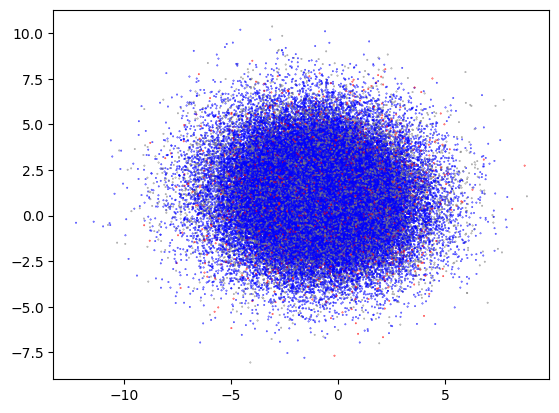

In [25]:
color = np.array(['blue'] * len(df))
color[df['bind_combined'] == 'strong_evidence'] = 'red'
color[df['bind_combined'] == 'weak_evidence'] = 'gray'
plt.scatter(embeddings[:,0], embeddings[:,1], s=.1, color=color)

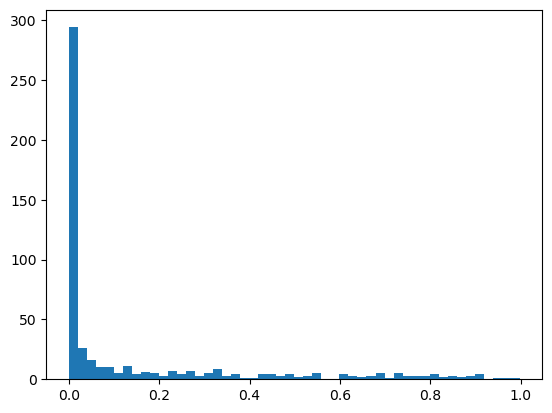

In [26]:
p_value = []

for i in range(embedding_dim):
    x = embeddings[:,i]
    # p = stats.mannwhitneyu(x[color=='red'], x[color=='blue']).pvalue.item()
    p = stats.ttest_ind(x[color=='red'], x[color=='blue']).pvalue.item()
    p_value.append(p)

plt.hist(p_value, 50);

In [14]:
q_value = stats.false_discovery_control(p_value, method='bh')
len(q_value[q_value < .05])

307

In [21]:
fpBits_all = np.load("data/ligend_fingerprints.npy")

In [15]:
(color=='red').sum()

np.int64(2895)

In [27]:
fpBits_all.shape, embeddings.shape

(torch.Size([79800, 2048]), torch.Size([79800, 512]))

In [28]:
embeddings = embeddings.detach().numpy()

In [55]:
n_train_per_class = 2600
n_repeat = 3

x0 = fpBits_all[df['Binding_validated_by_TSA'] == 'strong_evidence']
x1 = fpBits_all[df['Binding_validated_by_TSA'] == 'no_evidence']

result_df = pd.DataFrame(columns=['acc', 'sen', 'spc', 'prc', 'mcc'])

for i in tqdm(range(n_repeat)):
    (x0_train, x1_train), (x0_test, x1_test) = train_test_split([x0, x1], n_train_per_class)
    # (x0_test, x1_test), (_, _) = train_test_split([x0_test, x1_test], 100)

    # (x0_test, x1_test) = (x0_train, x1_train)
    
    X_train = np.concat([x0_train, x1_train])
    y_train = np.array([0] * len(x0_train) + [1] * len(x1_train))
    X_test = np.concat([x0_test, x1_test])
    y_test = np.array([0] * len(x0_test) + [1] * len(x1_test))

    # model = GradientBoostingClassifier()
    # model = RandomForestClassifier(n_estimators = 200, max_depth = 10) 
    model = SVC(kernel='rbf')
    # model = LogisticRegression()
    model.fit(X_train, y_train);
    y_hat = model.predict(X_test)
    
    acc, sen, spc, prc, mcc = classification_metrics(y_test, y_hat)
    # mcc = matthews_corrcoef(y_test, y_hat)
    result_df.loc[len(result_df)] = [acc, sen, spc, prc, mcc]

result_df.mean()

100%|██████████████████████████████████████████████| 3/3 [07:13<00:00, 144.38s/it]


acc    0.678322
sen    0.679550
spc    0.663812
prc    0.959835
mcc    0.193511
dtype: float64